# Unsupervised Color-Based Clustering of TV Show Posters with IMDb Metadata Analysis

## Table of Contents

- [Imports](#imports)
- [Global Variables](#global-variables)
- [Global Functions](#global-functions)
	- [File & API Functions](#file--api-functions)
	- [Process Functions](#process-functions)
		- [Analysis Functions](#analysis-functions)

# Imports

In [2]:
from bs4 import BeautifulSoup
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import cv2
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import random
import requests
import seaborn as sns
import warnings
import json

# Global Variables

In [3]:
warnings.filterwarnings('ignore')

imdbCSV = "CSV/imdb_episodes.csv"
"""
Determines what CSV file will be used as reference for the posters (images) from `imgDir` variable.
"""

imgDir = "imdb_episode_images"
"""
Defines the directory where the image samples are located. The image name will be used to determine its slug (`tconst`) in the CSV file defined in `imdbCSV` variable.
"""

'\nDefines the directory where the image samples are located. The image name will be used to determine its slug (`tconst`) in the CSV file defined in `imdbCSV` variable.\n'

# Global Functions

Defines the global functions that will be used in the succeeding code blocks. These functions are separated by category so that they will be easy to find when the need arises.

## File & API Functions

All the file and API related handling functions will be defined here.

In [ ]:
def get_random_images(filepath, n):
    # Get n images in the folder
    all_images = [f for f in os.listdir(filepath) if f.startswith('tt')]
    return random.sample(all_images, min(n, len(all_images)))

def extract_imdb_id(filename):
    # Extract the IMDB ID from the filename
    return filename.split('.')[0]

def get_imdb_data(imdb_id: str, csvPath: str) -> dict | None:
    """
    Fetches the relevant data from the IMDB CSV file.
    
    :param imdb_id: The IMDB ID of the show.
    :type imdb_id: str
    
    :param csvPath: The path to the IMDB CSV file.
    :type csvPath: str
    
    :return: The relevant data from the IMDB CSV file in a dictionary format.
    """
    try:
        tmpDf = pd.read_csv(csvPath)
        row = tmpDf[tmpDf["Slug"] == imdb_id]
        row = row.to_dict(orient='records')[0]
        
        genres = row.get('Genres', None)
        if genres:
            genres = eval(genres)
            
        rowData = {
            'imdb_id': imdb_id,
            'title': row.get('Title', None),
            'rating': row.get('Rating', 0),
            'date_published': row.get('Date', None),
            'genres': genres,
            'poster': row.get('Poster', None),
        }
        
        return rowData
    except Exception as e:
        print(f"Error processing {imdb_id}: {str(e)}")
        return None


## Process Functions

All processing related functions such as feature engineering, selection, and even dataset processes goes here.

In [26]:
def extract_color_features(image_path):
    # Extract color features from an image
    img = cv2.imread(image_path)
    if img is None:
        return None
    
    img_resized = cv2.resize(img, (224, 336))
    
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
    
    # Extract RGBW features
    features = {}
    r, g, b = cv2.split(img_rgb)
    w = (r + g + b) / 3  
    features = np.array([r.mean(), g.mean(), b.mean(), w.mean()])
    
    return features

def create_dataset(imgPath: str, dataPath:str, sampleSize: int = 100, save: bool = True):
    """
    Create datasets from images and their analysis.
    
    :param image_folder: Directory where the images are located.
    :type image_folder: str
    
    :param dataPath: Path to the IMDB CSV file. The CSV file is usually inside the "CSV" directory.
    :type dataPath: str
    
    :param sampleSize: Number of images to be analyzed. Default is 100.
    :type sampleSize: int
    
    :param save: If `True`, save the datasets to CSV files under CSV directory. Default is `True`.
    :type save: bool
    
    :return: DataFrames with IMDB data and color features.
    """
    images = get_random_images(imgPath, sampleSize)
    imdb_data = []
    feature_data = []
    
    for img in images:
        imdb_id = extract_imdb_id(img)
        show_data = get_imdb_data(imdb_id, dataPath)
        
        if show_data:
            img_path = os.path.join(imgPath, img)
            features = extract_color_features(img_path)

            if features is not None:  
                features_with_id = np.append(features, imdb_id)  
                feature_data.append(features_with_id)
                imdb_data.append(show_data)
    
    # Define column names for the feature DataFrame
    feature_columns = ['r_mean', 'g_mean', 'b_mean', 'w_mean', 'imdb_id']
    
    imdb_df = pd.DataFrame(imdb_data)
    feature_df = pd.DataFrame(feature_data, columns=feature_columns)
    
    # Save datasets
    if save:
        if not os.path.exists('CSV'):
            os.makedirs('CSV')
        imdb_df.to_csv('CSV/df_data.csv', index=False)
        feature_df.to_csv('CSV/feature_data.csv', index=False)
    
    return imdb_df, feature_df


### Analysis Functions

Functions that analyzes data are defined in this subcategory of [`Process Functions`](#process-functions) category.

In [25]:
def perform_pca_analysis(feature_df):
    # Prepare feature matrix
    X = feature_df.drop('imdb_id', axis=1)
    
    # Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Perform PCA with only 2 components
    pca = PCA(n_components=2)  # Explicitly set to 2 components
    X_pca = pca.fit_transform(X_scaled)
    
    # Get cumulative variance ratio
    cum_var_ratio = np.cumsum(pca.explained_variance_ratio_)
    
    # Since we're only using 2 components, n_components is fixed at 2
    n_components = 2
    
    return pca, X_pca, n_components

def analyze_clusters_with_metadata(X_pca, metadata_values, metadata_name, clustering_method='kmeans', n_clusters=3):
    """
    Print statistical analysis of metadata distribution across clusters
    """
    if clustering_method == 'kmeans':
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(X_pca)
    elif clustering_method == 'hierarchical':
        Z = linkage(X_pca, method='ward')
        labels = fcluster(Z, n_clusters, criterion='maxclust')
    else:  # dbscan
        dbscan = DBSCAN(eps=0.5, min_samples=5)
        labels = dbscan.fit_predict(X_pca)
    
    # Create a DataFrame with clusters and metadata
    df_analysis = pd.DataFrame({
        'Cluster': labels,
        metadata_name: metadata_values
    })
    
    # Calculate statistics for each cluster
    cluster_stats = df_analysis.groupby('Cluster')[metadata_name].agg(['mean', 'std', 'count'])
    print(f"\nCluster Statistics for {metadata_name}:")
    print(cluster_stats)
    
    # Perform one-way ANOVA to test for significant differences
    from scipy import stats
    clusters = [group[metadata_name].values for name, group in df_analysis.groupby('Cluster')]
    f_stat, p_value = stats.f_oneway(*clusters)
    print(f"\nOne-way ANOVA test results:")
    print(f"F-statistic: {f_stat:.4f}")
    print(f"p-value: {p_value:.4f}")

def analyze_genre_distribution(X_pca, genres_list, clustering_method='kmeans', n_clusters=3):
    """
    Analyze the distribution of genres across clusters
    """
    # Get clustering labels
    if clustering_method == 'kmeans':
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(X_pca)
    elif clustering_method == 'hierarchical':
        Z = linkage(X_pca, method='ward')
        labels = fcluster(Z, n_clusters, criterion='maxclust')
    else:  # dbscan
        dbscan = DBSCAN(eps=0.5, min_samples=5)
        labels = dbscan.fit_predict(X_pca)
    
    # Create a DataFrame with all genres (not just primary)
    all_genres = []
    for genres in genres_list:
        all_genres.extend(genres)
    unique_genres = sorted(list(set(all_genres)))
    
    # Create binary columns for each genre
    genre_matrix = np.zeros((len(genres_list), len(unique_genres)))
    for i, show_genres in enumerate(genres_list):
        for genre in show_genres:
            j = unique_genres.index(genre)
            genre_matrix[i, j] = 1
    
    # Create DataFrame with cluster labels and genre indicators
    genre_df = pd.DataFrame(genre_matrix, columns=unique_genres)
    genre_df['Cluster'] = labels
    
    # Calculate genre proportions for each cluster
    cluster_stats = []
    for cluster in range(n_clusters):
        cluster_data = genre_df[genre_df['Cluster'] == cluster]
        genre_props = cluster_data[unique_genres].mean()
        cluster_stats.append(genre_props)
    
    cluster_stats_df = pd.DataFrame(cluster_stats, 
                                  index=[f'Cluster {i}' for i in range(n_clusters)])
    
    print("\nGenre proportions in each cluster:")
    print(cluster_stats_df.round(3))
    
    # Chi-square test for independence
    from scipy.stats import chi2_contingency
    
    contingency_table = pd.crosstab(genre_df['Cluster'], 
    genre_df[unique_genres].idxmax(axis=1))
    
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)
    print(f"\nChi-square test for genre independence across clusters:")
    print(f"Chi-square statistic: {chi2:.2f}")
    print(f"p-value: {p_value:.4f}")


### Plotting Functions

Functions that creates plots goes here.

In [24]:
def plot_explained_variance(pca, n_components):
    """Plot explained variance ratio as a bar graph up to n_components."""
    explained_variance = pca.explained_variance_ratio_[:n_components]  
    
    plt.figure(figsize=(10, 5))
    plt.bar(range(1, n_components + 1), explained_variance, alpha=0.7, color='blue', align='center')
    
    plt.title('Explained Variance Ratio by Principal Component (Up to 80% Variance)')
    plt.xlabel('Principal Component')
    plt.ylabel('Explained Variance Ratio')
    plt.xticks(range(1, n_components + 1))  
    plt.grid(axis='y', linestyle='--', alpha=0.7)  
    plt.show()
    
def plot_cumulative_variance(pca):
    """Plot cumulative explained variance ratio."""
    plt.figure(figsize=(10, 5))
    plt.plot(range(1, len(pca.explained_variance_ratio_) + 1),
            np.cumsum(pca.explained_variance_ratio_), 'bo-')
    plt.title('Cumulative Explained Variance Ratio')
    plt.xlabel('Number of Components')
    plt.ylabel('Cumulative Explained Variance Ratio')
    plt.axhline(y=0.8, color='r', linestyle='--', label='80% Threshold')
    plt.legend()
    plt.show()
    
def plot_pca_features(pca, X_pca, n_components):
    """Plot features on principal components."""
    plt.figure(figsize=(12, 8))
    
    df_pca = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
    
    plt.scatter(df_pca["PC1"], df_pca["PC2"], alpha=0.7, edgecolors='k')
    
    plt.xlabel('First Principal Component')
    plt.ylabel('Second Principal Component')
    plt.title('Features on First Two Principal Components')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

def plot_feature_loadings(pca, feature_names, n_components):
    """Plot feature loadings for significant components."""
    loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
    
    # Create loadings table
    loadings_df = pd.DataFrame(
        loadings[:, :n_components],
        columns=[f'PC{i+1}' for i in range(n_components)],
        index=feature_names
    )
    return loadings_df

def plot_clustering_comparison(X_pca, n_components):
    """Plot different clustering methods side by side in 2D."""
    fig = plt.figure(figsize=(20, 6))
    
    # K-means
    ax1 = fig.add_subplot(131)
    kmeans = KMeans(n_clusters=3, random_state=42)
    kmeans_labels = kmeans.fit_predict(X_pca[:, :n_components])
    scatter1 = ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis')
    ax1.set_title('K-means Clustering')
    ax1.set_xlabel('PC1')
    ax1.set_ylabel('PC2')
    
    # Hierarchical
    ax2 = fig.add_subplot(132)
    Z = linkage(X_pca[:, :n_components], method='ward')
    hier_labels = fcluster(Z, 3, criterion='maxclust')
    scatter2 = ax2.scatter(X_pca[:, 0], X_pca[:, 1], c=hier_labels, cmap='viridis')
    ax2.set_title('Hierarchical Clustering')
    ax2.set_xlabel('PC1')
    ax2.set_ylabel('PC2')
    
    # DBSCAN
    ax3 = fig.add_subplot(133)
    dbscan = DBSCAN(eps=0.5, min_samples=5)
    dbscan_labels = dbscan.fit_predict(X_pca[:, :n_components])
    scatter3 = ax3.scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, cmap='viridis')
    ax3.set_title('DBSCAN Clustering')
    ax3.set_xlabel('PC1')
    ax3.set_ylabel('PC2')
    
    # Add colorbars
    fig.colorbar(scatter1, ax=ax1, label='Cluster')
    fig.colorbar(scatter2, ax=ax2, label='Cluster')
    fig.colorbar(scatter3, ax=ax3, label='Cluster')
    
    plt.tight_layout()
    plt.show()

def plot_clusters_with_metadata(X_pca, metadata_values, metadata_name, clustering_method='kmeans', n_clusters=3):
    """
    Plot clusters with metadata values represented by color intensity
    
    Parameters:
    -----------
    X_pca : array-like
        PCA-transformed feature data
    metadata_values : array-like
        Values to be represented by color intensity (e.g., ratings or years)
    metadata_name : str
        Name of the metadata being visualized (for labels)
    clustering_method : str
        Clustering method to use ('kmeans', 'hierarchical', or 'dbscan')
    n_clusters : int
        Number of clusters for kmeans and hierarchical clustering
    """
    plt.figure(figsize=(15, 6))
    
    # Plot 1: Clusters
    plt.subplot(121)
    if clustering_method == 'kmeans':
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(X_pca)
    elif clustering_method == 'hierarchical':
        Z = linkage(X_pca, method='ward')
        labels = fcluster(Z, n_clusters, criterion='maxclust')
    else:  # dbscan
        dbscan = DBSCAN(eps=0.5, min_samples=5)
        labels = dbscan.fit_predict(X_pca)
    
    scatter1 = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis')
    plt.colorbar(scatter1, label='Cluster')
    plt.title(f'{clustering_method.title()} Clusters')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    
    # Plot 2: Metadata overlay
    plt.subplot(122)
    scatter2 = plt.scatter(X_pca[:, 0], X_pca[:, 1], 
                          c=metadata_values, 
                          cmap='RdYlBu_r',  # Red-Yellow-Blue colormap, reversed
                          alpha=0.6)
    plt.colorbar(scatter2, label=metadata_name)
    plt.title(f'Clusters with {metadata_name} Overlay')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    
    plt.tight_layout()
    plt.show()

def plot_clusters_with_genres(X_pca, genres_list, clustering_method='kmeans', n_clusters=3):
    """
    Plot clusters with primary genre overlay
    
    Parameters:
    -----------
    X_pca : array-like
        PCA-transformed feature data
    genres_list : list
        List of genre lists for each data point
    clustering_method : str
        Clustering method to use ('kmeans', 'hierarchical', or 'dbscan')
    n_clusters : int
        Number of clusters for kmeans and hierarchical clustering
    """
    # Get primary genre for each show
    primary_genres = [genres[0] if genres else 'Unknown' for genres in genres_list]
    
    # Get unique genres and create a color map
    unique_genres = sorted(list(set(primary_genres)))
    genre_to_num = {genre: i for i, genre in enumerate(unique_genres)}
    genre_values = [genre_to_num[genre] for genre in primary_genres]
    
    # Create custom colormap with distinct colors
    import matplotlib.colors as mcolors
    n_genres = len(unique_genres)
    colors = plt.cm.rainbow(np.linspace(0, 1, n_genres))
    cmap = mcolors.ListedColormap(colors)
    
    plt.figure(figsize=(15, 6))
    
    # Plot 1: Clusters
    plt.subplot(121)
    if clustering_method == 'kmeans':
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(X_pca)
    elif clustering_method == 'hierarchical':
        Z = linkage(X_pca, method='ward')
        labels = fcluster(Z, n_clusters, criterion='maxclust')
    else:  # dbscan
        dbscan = DBSCAN(eps=0.5, min_samples=5)
        labels = dbscan.fit_predict(X_pca)
    
    scatter1 = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis')
    plt.colorbar(scatter1, label='Cluster')
    plt.title(f'{clustering_method.title()} Clusters')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    
    # Plot 2: Genre overlay
    plt.subplot(122)
    scatter2 = plt.scatter(X_pca[:, 0], X_pca[:, 1], 
                          c=genre_values, 
                          cmap=cmap,
                          alpha=0.6)
    
    # Create custom colorbar with genre labels
    cbar = plt.colorbar(scatter2, ticks=range(len(unique_genres)))
    cbar.set_label('Primary Genre')
    cbar.ax.set_yticklabels(unique_genres)
    
    plt.title('Clusters with Genre Overlay')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    
    plt.tight_layout()
    plt.show()
    
    # Print genre distribution analysis
    print("\nGenre Distribution across Clusters:")
    cluster_genre_df = pd.DataFrame({
        'Cluster': labels,
        'Genre': primary_genres
    })
    
    # Create a cross-tabulation of clusters and genres
    cluster_genre_table = pd.crosstab(
        cluster_genre_df['Cluster'],
		cluster_genre_df['Genre'], 
		normalize='index'
  	) * 100
    
    print("\nPercentage of genres in each cluster:")
    print(cluster_genre_table.round(2))


# Load Data

Steps 1 to 3 are done here; where data is "gathered" by loading a CSV file, alongside its feature extraction.

In [29]:
print("Step 1: Gathering data...")
imdb_df, feature_df = create_dataset(imgDir, imdbCSV, save = False)

Step 1: Gathering data...


In [30]:
print("\nIMDB Data Sample:")
imdb_df.head()


IMDB Data Sample:


,imdb_id,title,rating,date_published,genres,poster
0,tt4734840,Lift Girl,7.4,2015-08-06,"[Action, Comedy]",imdb_episode_images\tt4734840.jpg
1,tt2121908,Design with the Other 90%,6.4,2011-11-29,[Documentary],imdb_episode_images\tt2121908.jpg
2,tt13032762,Black Widows,6.9,2020-12-18,"[Crime, Drama, Mystery]",imdb_episode_images\tt13032762.jpg
3,tt26629862,Pigerne fra Englandsbåden,5.8,2023-11-29,"[Crime, Drama]",imdb_episode_images\tt26629862.jpg
4,tt3844996,Delo Batagami,4.4,2014-10-25,"[Action, Drama, Thriller]",imdb_episode_images\tt3844996.jpg


In [31]:
print("\nFeature Data Sample:")
feature_df.head()


Feature Data Sample:


,r_mean,g_mean,b_mean,w_mean,imdb_id
0,85.69706632653062,104.34192974064626,88.06228741496598,38.16187907454648,tt4734840
1,79.75904815051021,63.19832855017007,40.243489583333336,34.57715950963719,tt2121908
2,94.11273650085035,77.78380102040816,72.40646258503402,36.06245128259637,tt13032762
3,136.59855973639455,143.36612457482994,142.30762383078232,39.57036121740363,tt26629862
4,85.65598426870748,83.10093803146259,82.31786777210884,32.37867152069161,tt3844996


In [32]:
# 4-8. PCA Analysis
print("\nStep 4-8: Performing PCA analysis...")
feature_names = feature_df.drop('imdb_id', axis=1).columns
pca, X_pca, n_components = perform_pca_analysis(feature_df)

# Set display precision for floating-point numbers
pd.set_option('display.float_format', '{:.6f}'.format)


print("\nExplained variance ratios:")
evr = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(pca.explained_variance_ratio_))],
    'Explained Variance Ratio': pca.explained_variance_ratio_
}).set_index('Principal Component')
evr


Step 4-8: Performing PCA analysis...

Explained variance ratios:


,Explained Variance Ratio
Principal Component,
PC1,0.808112
PC2,0.095818


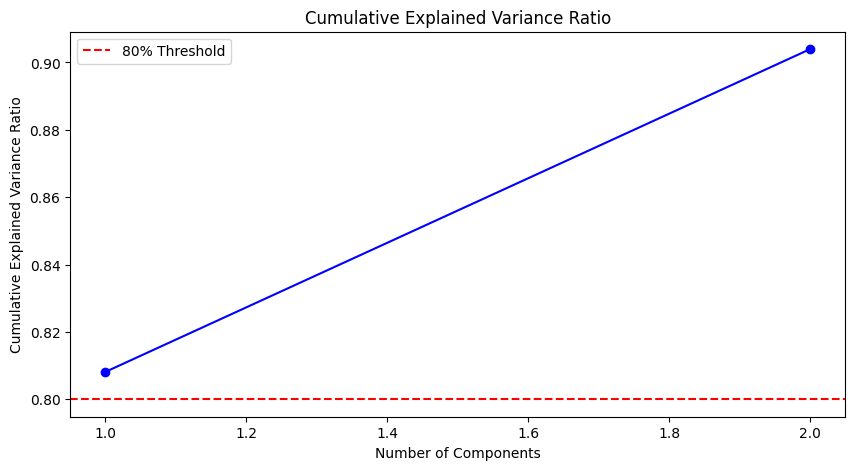

In [33]:
plot_cumulative_variance(pca)

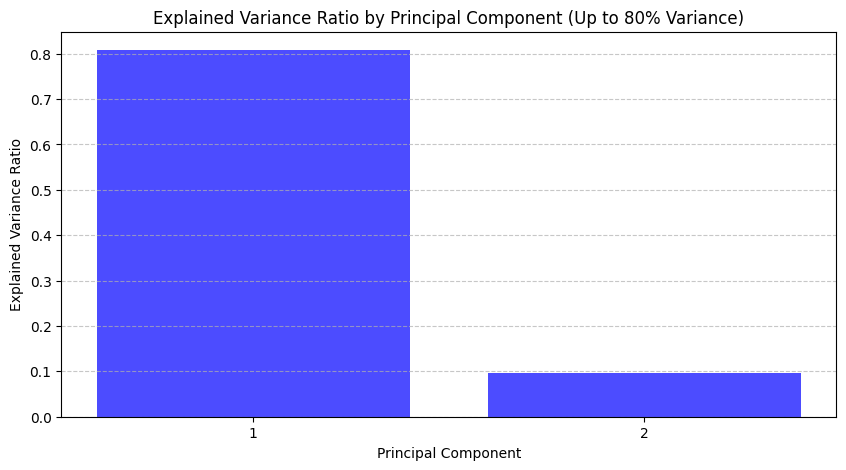

In [34]:
plot_explained_variance(pca, n_components)

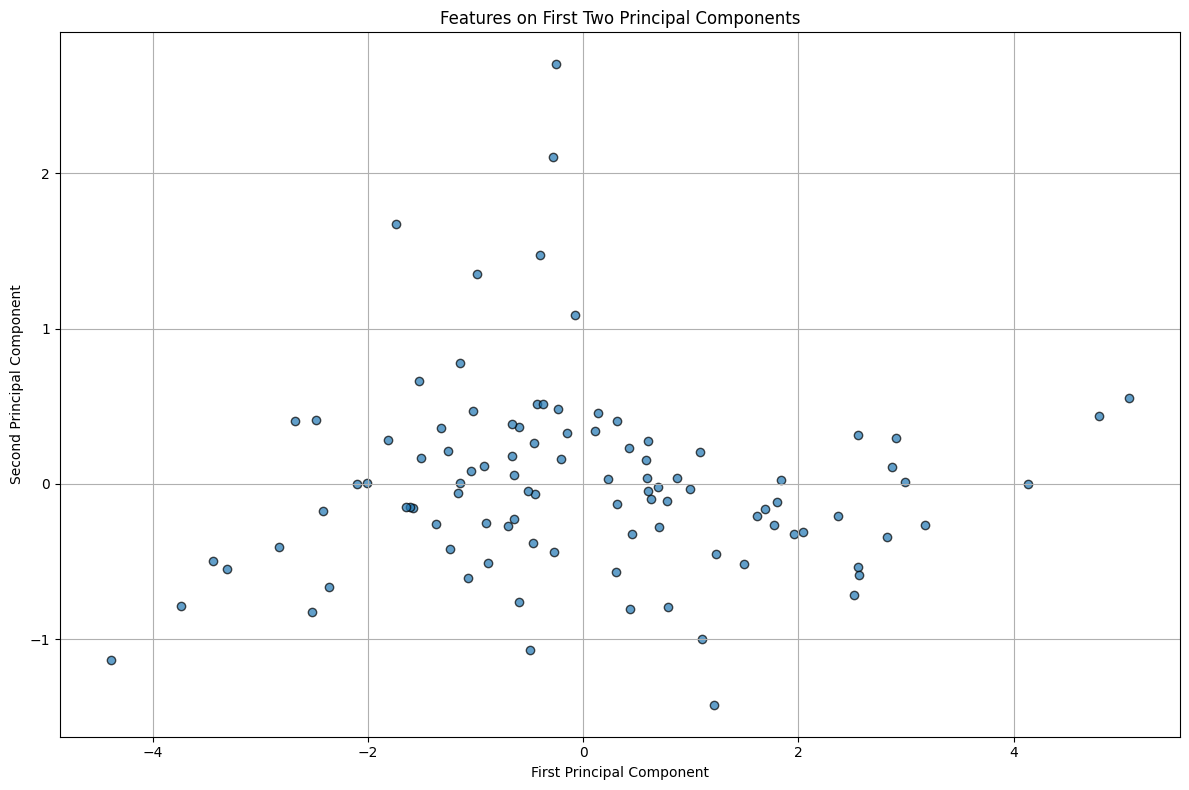

In [36]:
plot_pca_features(pca, X_pca, n_components)

In [37]:
loadings_df = plot_feature_loadings(pca, feature_names, n_components)
loadings_df


,PC1,PC2
r_mean,0.902385,0.163894
g_mean,0.949007,-0.244870
b_mean,0.901569,-0.325910
w_mean,0.858697,0.440571


In [38]:
loadings_df.sort_values(by="PC1", ascending=False).head(10)

,PC1,PC2
g_mean,0.949007,-0.244870
r_mean,0.902385,0.163894
b_mean,0.901569,-0.325910
w_mean,0.858697,0.440571



Step 9-12: Performing clustering analysis...


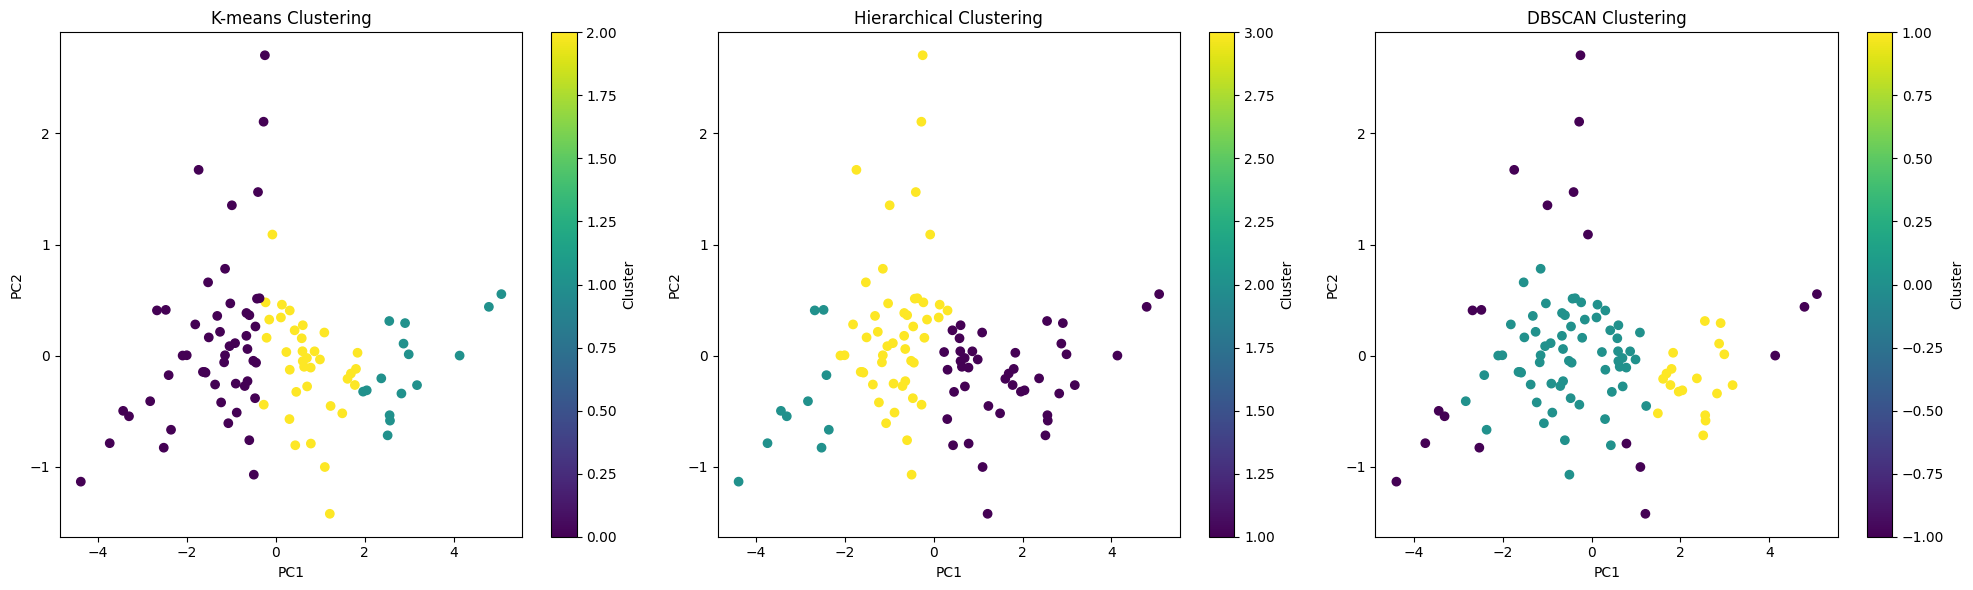

In [39]:
# 9-12. Clustering Analysis
print("\nStep 9-12: Performing clustering analysis...")
plot_clustering_comparison(X_pca, n_components)

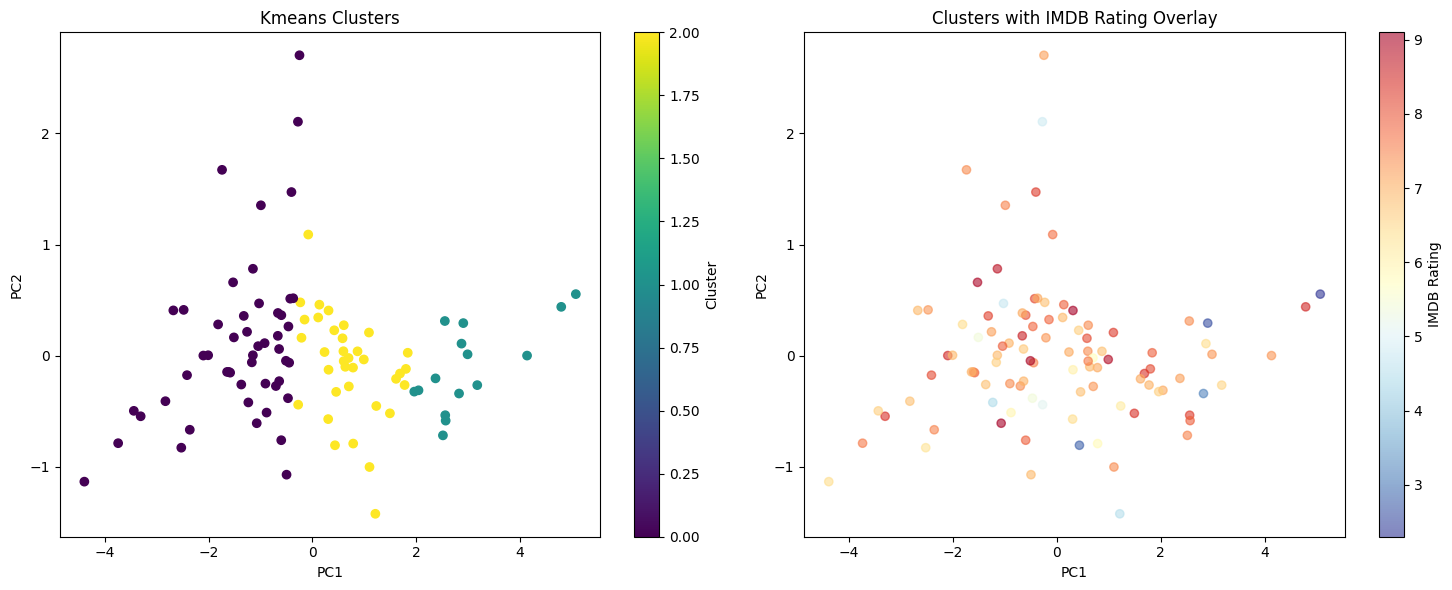


Cluster Statistics for IMDB Rating:
            mean      std  count
Cluster                         
0       7.220000 1.073997     50
1       6.406667 2.013691     15
2       7.042857 1.247182     35

One-way ANOVA test results:
F-statistic: 2.2285
p-value: 0.1132


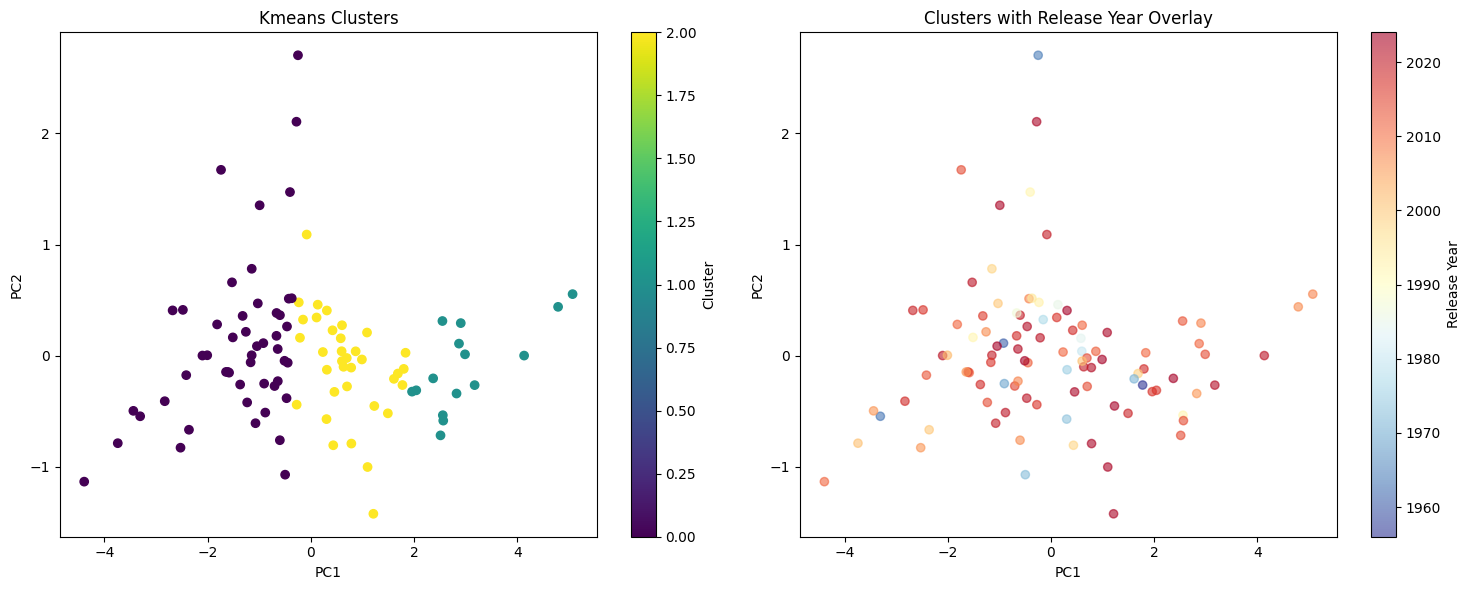


Cluster Statistics for Release Year:
               mean       std  count
Cluster                             
0       2007.320000 16.766634     50
1       2012.533333  7.918032     15
2       2006.400000 19.362183     35

One-way ANOVA test results:
F-statistic: 0.7366
p-value: 0.4814


In [40]:
# Extract year from date_published
imdb_df['year'] = pd.to_datetime(imdb_df['date_published']).dt.year

# Merge feature data with IMDB data
merged_df = pd.merge(feature_df, imdb_df, on='imdb_id')

# Visualize clusters with ratings
plot_clusters_with_metadata(X_pca, merged_df['rating'], 'IMDB Rating')
analyze_clusters_with_metadata(X_pca, merged_df['rating'], 'IMDB Rating')

# Visualize clusters with years
plot_clusters_with_metadata(X_pca, merged_df['year'], 'Release Year')
analyze_clusters_with_metadata(X_pca, merged_df['year'], 'Release Year')

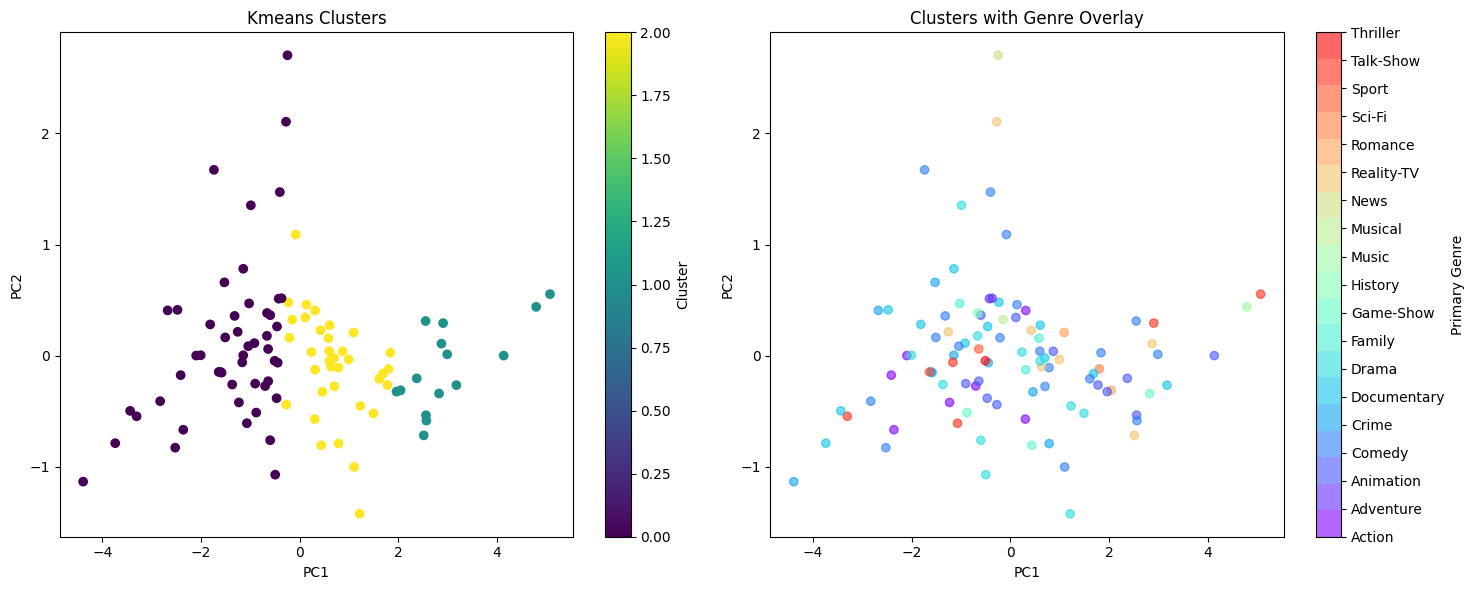


Genre Distribution across Clusters:

Percentage of genres in each cluster:
Genre      Action  Adventure  Animation    Comedy     Crime  Documentary  \
Cluster                                                                    
0       10.000000   4.000000   8.000000 16.000000 10.000000    16.000000   
1        0.000000   0.000000  26.670000 20.000000  0.000000     6.670000   
2        5.710000   0.000000  11.430000 25.710000  5.710000    11.430000   

Genre       Drama   Family  Game-Show  History    Music  Musical     News  \
Cluster                                                                     
0       12.000000 2.000000   2.000000 2.000000 0.000000 0.000000 2.000000   
1        0.000000 0.000000   6.670000 0.000000 6.670000 0.000000 0.000000   
2       14.290000 5.710000   2.860000 0.000000 0.000000 2.860000 0.000000   

Genre    Reality-TV  Romance   Sci-Fi    Sport  Talk-Show  Thriller  
Cluster                                                              
0          4.0000

In [41]:
# Visualize clusters with genres
plot_clusters_with_genres(X_pca, merged_df['genres'])
analyze_genre_distribution(X_pca, merged_df['genres'])